# Part 1: Logistic Regression

In [1]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [2]:
# Load the Breast Cancer Wisconsin dataset
data = load_breast_cancer()
X = data.data
y = data.target

In [3]:
# TODO: Split the dataset into training and testing sets using an 80-20 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2)

In [4]:
# Normalize the feature data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
# Implement Logistic Regression algorithm

# TODO: Implement the sigmoid function. Refer to the formula in the HW4.docx file
def sigmoid(z):
    # make sure to use the z variable in the formula
    formula = 1 / (1 + np.exp(-z))

    return formula

def logistic_regression(X, y, learning_rate, num_iterations):
    n_samples, n_features = X.shape
    weights = np.zeros(n_features)
    bias = 0

    # we need to update the weights and bias using gradient descent. Complete the code below
    for _ in range(num_iterations):
        # TODO: combine the inputs and weights together, and then add bias. Assign this value to z
        z = np.dot(X, weights) + bias

        # TODO: need to output probabilities betwen 0 and 1 (HINT: use the sigmoid function)
        y_predicted = sigmoid(z)

        # Compute the gradients

        # TODO: dw is the gradient of the loss function w.r.t. the weights
        dw = (1/n_samples) * np.dot(X.T, y_predicted - y)

        # TODO: db is the gradient of the loss function w.r.t. the bias
        db = (1/n_samples) * np.sum(y_predicted - y)

        # TODO: update the weights and bias using the computed gradients (HINT: use the learning rate)
        weights -= learning_rate * dw
        bias -= learning_rate * db

    return weights, bias


In [8]:
# Train Logistic Regression model
# TODO: Find good values for learning_rate and num_iterations
learning_rate = 0.01
num_iterations = 1000
weights, bias = logistic_regression(X_train_scaled, y_train, learning_rate, num_iterations)

# Predict class labels using trained model
def predict(X, weights, bias):
    z = np.dot(X, weights) + bias
    y_predicted = sigmoid(z)
    y_predicted_cls = [1 if i > 0.5 else 0 for i in y_predicted]
    return y_predicted_cls

In [9]:
y_pred = predict(X_test_scaled, weights, bias)

# Evaluate the model's performance
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
acc = np.mean(y_pred == y_test)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Accuracy:", acc)

Precision: 0.9857142857142858
Recall: 0.9857142857142858
F1 Score: 0.9857142857142858
Accuracy: 0.9824561403508771


# Part 2: Data Preperation

In [10]:
# First, make sure the values of X_train, X_test, y_train, y_test are set correctly from Part 1 and not overwritten
# If necessary, go back and rerun the original cell to make sure you have those correct values
print(X_train)
print(X_test)
print(y_train)
print(y_test)

[[2.161e+01 2.228e+01 1.444e+02 ... 2.422e-01 3.828e-01 1.007e-01]
 [1.959e+01 1.815e+01 1.307e+02 ... 2.247e-01 3.643e-01 9.223e-02]
 [1.243e+01 1.700e+01 7.860e+01 ... 2.832e-02 1.901e-01 5.932e-02]
 ...
 [1.236e+01 1.854e+01 7.901e+01 ... 8.442e-02 2.983e-01 7.185e-02]
 [1.989e+01 2.026e+01 1.305e+02 ... 1.613e-01 2.549e-01 9.136e-02]
 [1.882e+01 2.197e+01 1.237e+02 ... 1.708e-01 3.007e-01 8.314e-02]]
[[1.075e+01 1.497e+01 6.826e+01 ... 3.413e-02 2.300e-01 6.769e-02]
 [1.369e+01 1.607e+01 8.784e+01 ... 6.987e-02 3.323e-01 7.701e-02]
 [9.731e+00 1.534e+01 6.378e+01 ... 1.571e-01 3.108e-01 1.259e-01]
 ...
 [1.283e+01 1.573e+01 8.289e+01 ... 9.783e-02 3.006e-01 7.802e-02]
 [1.461e+01 1.569e+01 9.268e+01 ... 5.813e-02 2.530e-01 5.695e-02]
 [2.175e+01 2.099e+01 1.473e+02 ... 1.841e-01 2.833e-01 8.858e-02]]
[0 0 1 1 0 1 1 0 0 1 0 1 1 0 0 0 1 1 1 1 0 0 1 1 0 0 0 0 1 1 0 1 1 1 0 1 0
 1 0 1 0 0 0 0 1 1 0 1 1 0 1 0 1 1 0 1 1 1 1 1 1 0 0 1 0 1 0 0 0 0 1 1 1 1
 0 1 0 0 1 1 0 1 1 1 0 1 1 1 1 0 1

In [14]:
# TODO: Rewrite the logistic regression code to include test evals at every n iterations
# Should now return test accuracy every n iterations
def logistic_regression_with_eval(X_train, y_train, X_test, y_test, learning_rate, num_iterations, eval_every=1):
    n_samples, n_features = X_train.shape
    weights = np.zeros(n_features)
    bias = 0
    train_acc_all = []
    test_acc_all = []

    # Fill in with old solution
    for i in range(num_iterations):
        # Add your code from above
        z = np.dot(X_train,weights) + bias

        y_predicted = sigmoid(z)
        
        dw = (1/n_samples) * np.dot(X_train.T, y_predicted - y_train)
        db = (1/n_samples) * np.sum(y_predicted - y_train)

        weights -= learning_rate * dw
        bias -= learning_rate * db
        # Add new code here
        if i % eval_every == 0:
          train_pred = predict(X_train, weights, bias)
          test_pred = predict(X_test, weights, bias)
          train_acc_all.append(accuracy_score(y_train, train_pred))
          test_acc_all.append(accuracy_score(y_test, test_pred))

    return weights, bias, train_acc_all, test_acc_all

In [15]:
import matplotlib.pyplot as plt

In [16]:
# Take your solution from above and plot the train and test curves
# TODO: Copy hyperparameters from your solution above
learning_rate = 0.01
num_iterations = 1000
weights_scaled, bias_scaled, train_acc_scaled, test_acc_scaled = logistic_regression_with_eval(
    X_train_scaled, y_train, X_test_scaled, y_test, learning_rate, num_iterations, eval_every=1)

# Make sure you get the same values as before
y_pred = predict(X_test_scaled, weights_scaled, bias_scaled)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
acc = np.mean(y_pred == y_test)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("Accuracy:", acc)

Precision: 0.9857142857142858
Recall: 0.9857142857142858
F1 Score: 0.9857142857142858
Accuracy: 0.9824561403508771


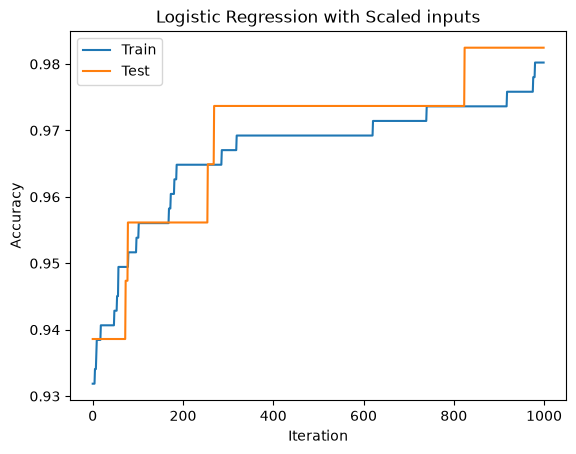

In [19]:
# TODO:
# Using Matplotlib, make a plot with #iterations on the x axis and train and test accuracy on the y_axis
# Recall, we asked you to make simple plots in HW1
plt.title('Logistic Regression with Scaled inputs')
plt.xlabel('Iteration')
plt.ylabel('Accuracy')
plt.plot(train_acc_scaled, label = 'Train')
plt.plot(test_acc_scaled, label = 'Test')
plt.legend()
plt.show()

C:\Users\aptls\AppData\Local\Temp\ipykernel_22304\3634285251.py:6: RuntimeWarning: overflow encountered in exp
  formula = 1 / (1 + np.exp(-z))
C:\Users\aptls\AppData\Local\Temp\ipykernel_22304\3634285251.py:6: RuntimeWarning: overflow encountered in exp
  formula = 1 / (1 + np.exp(-z))
C:\Users\aptls\AppData\Local\Temp\ipykernel_22304\3634285251.py:6: RuntimeWarning: overflow encountered in exp
  formula = 1 / (1 + np.exp(-z))
C:\Users\aptls\AppData\Local\Temp\ipykernel_22304\3634285251.py:6: RuntimeWarning: overflow encountered in exp
  formula = 1 / (1 + np.exp(-z))
C:\Users\aptls\AppData\Local\Temp\ipykernel_22304\3634285251.py:6: RuntimeWarning: overflow encountered in exp
  formula = 1 / (1 + np.exp(-z))
C:\Users\aptls\AppData\Local\Temp\ipykernel_22304\3634285251.py:6: RuntimeWarning: overflow encountered in exp
  formula = 1 / (1 + np.exp(-z))
C:\Users\aptls\AppData\Local\Temp\ipykernel_22304\3634285251.py:6: RuntimeWarning: overflow encountered in exp
  formula = 1 / (1 + np.e

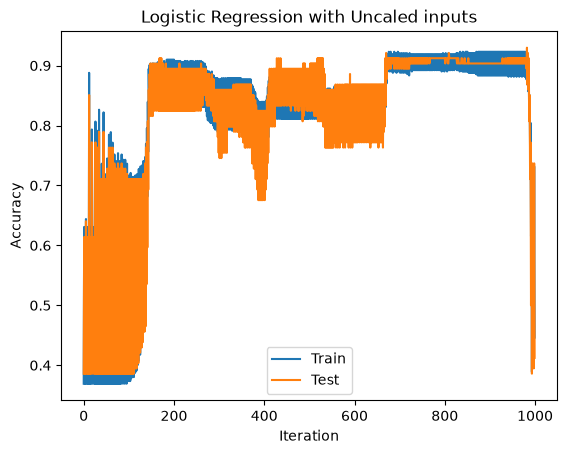

In [20]:
# TODO - re-train and replot logistic regression without doing any input rescaling
# This should mostly be copying code from above but using the unscaled data
weights_unscaled, bias_unscaled, train_acc_unscaled, test_acc_unscaled = logistic_regression_with_eval(
    X_train, y_train, X_test, y_test, learning_rate, num_iterations, eval_every=1)

plt.title('Logistic Regression with Uncaled inputs')
plt.xlabel('Iteration')
plt.ylabel('Accuracy')
plt.plot(train_acc_unscaled, label= 'Train')
plt.plot(test_acc_unscaled, label = 'Test')
plt.legend()
plt.show()

What do you notice about the training curves and accuracy? (Write a few sentences comparing them for scaled vs unscaled data).

TODO: With scaled data, the training and test accuracies increased and went to 98%. However, with unscaled data, both accuracies fluctuated 
widely and were lower. Without scaling, large feature values can cause overly large weight updates at the same learning rate making training less stable. 

Examine the weights for both the scaled and unscaled logistic regression? What do you notice?

In [21]:
# Compare weights
print(weights_scaled)
print(weights_unscaled)

[-0.37048452 -0.32197966 -0.36669708 -0.36530084 -0.14273777 -0.12880038
 -0.29942574 -0.39259543 -0.10411011  0.15116322 -0.34372293  0.00752309
 -0.2865115  -0.30023482 -0.00333015  0.10681516  0.07714479 -0.06905189
  0.05533183  0.16684214 -0.4466882  -0.39608542 -0.42874332 -0.41723048
 -0.31439013 -0.21208474 -0.28899225 -0.41189346 -0.29230369 -0.12255659]
[ 2.81710067e+00  3.77951907e+00  1.62771225e+01  5.54154153e+00
  2.53134057e-02 -1.44165083e-02 -5.60496844e-02 -2.34760811e-02
  4.90932049e-02  2.00640331e-02 -2.98163151e-03  2.77703741e-01
 -1.89076612e-01 -8.90035735e+00  1.19517835e-03 -4.02708849e-03
 -7.86917752e-03 -1.07054414e-03  3.59936466e-03  1.87516240e-04
  2.94311621e+00  4.87101477e+00  1.62827469e+01 -1.11175738e+01
  3.09704415e-02 -6.03059189e-02 -1.17236605e-01 -2.75809524e-02
  6.26585328e-02  1.73243185e-02]


TODO: The weights for the scaled data are relatively small ranging from around -0.45 to 0.17. The unscaled weights much more widely
from about -11 to 16. These differences reflect both the different feature scales and the unstable training observed with unscaled data at the same
learning rate. Since scaling changes the units of the inputs.

# Part 3: Perceptron

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [23]:
# TODO: Concatenate 1's to the X_train_scaled and X_test_scaled from Part 1
# Hint: You'll probably want to use the numpy concatenate operation
X_train_wones = np.concatenate((X_train_scaled, np.ones((X_train_scaled.shape[0],1))), axis = 1)
X_test_wones = np.concatenate((X_test_scaled, np.ones((X_test_scaled.shape[0],1))), axis = 1)

In [24]:
# TODO: Define the Perceptron class including an __init__ function and a forward function
# Hint: If you aren't familiar with using Python classes, now's a good time to read about
#       them. You'll use them more in future assignments. Many good resources exist, e.g.:
#       https://realpython.com/python-classes/
class Perceptron():
    # TODO: initialize the weight vector w
    def __init__(self, input_size):
        self.w = np.zeros(input_size)

    # TODO: classify a single example x using sgn(𝐰^T x) or sgn(𝐰^T x + b)
    # Hint: make sure the output labels are correct
    def forward(self, x):
        score = np.dot(x, self.w)
        return 1 if score >= 0 else -1

    # Implement the perceptron learning algorithm from slides
    def update(self, x, y, learning_rate):
        y_signed = -1 if y == 0 else 1
        prediction = self.forward(x)
        if y_signed != prediction:
            self.w += learning_rate * y_signed * x


In [25]:
# Train the model
# TODO: Find good values for learning_rate and num_iterations
learning_rate = 0.01
num_iterations = 100
input_size = X_train_wones.shape[1] # Note this is the input size with the 1's trick
perceptron = Perceptron(input_size)
for _ in range(num_iterations):
  for x_i, y_i in zip(X_train_wones, y_train):
    perceptron.update(x_i, y_i, learning_rate)

In [28]:
# Evaluate the model
# Should get around 95% accuracy
correct_count = 0
for x_i, y_i in zip(X_test_wones, y_test):
  correct = perceptron.forward(x_i) == (-1 if y_i == 0 else 1)
  if correct:
    correct_count += 1
accuracy = float(correct_count) / len(y_test)
print("Test accuracy: %f" % accuracy)

Test accuracy: 0.964912
